# Part E: KNN, Optimized Combined (k=25, Manhattan Basis, Distance Weighting)

This variation combines all optimal dimensions: shifting the neighborhood size to $k=25$ (Bias-Variance Regularization), applying Manhattan ($L_1$) distance basis, and inverse-distance weighting.


## 1. Environment Setup & Library Ingestion


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from IPython.display import display

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Preprocessed Data Ingestion


In [2]:
df_train = pd.read_csv('credit_train_preprocessed.csv')
df_test = pd.read_csv('credit_test_preprocessed.csv')

X_train = df_train.drop(columns=['dpnm'])
y_train = df_train['dpnm']
X_test = df_test.drop(columns=['dpnm'])
y_test = df_test['dpnm']

print(f"Training Matrix (X_train): {X_train.shape[0]:,} rows x {X_train.shape[1]} features")
print(f"Testing Matrix (X_test):   {X_test.shape[0]:,} rows x {X_test.shape[1]} features")


Training Matrix (X_train): 37,336 rows x 30 features
Testing Matrix (X_test):   5,993 rows x 30 features


## 3. Model Instantiation & Training Profile


In [3]:
# Instantiating configured KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=25,
    weights='distance',
    metric='manhattan',
    p=1,
    n_jobs=-1
)

start_train = time.time()
knn_model.fit(X_train, y_train)
fit_time = time.time() - start_train

start_infer = time.time()
probs = knn_model.predict_proba(X_test)[:, 1]
preds = (probs >= 0.5).astype(int)
infer_time = time.time() - start_infer

print(f"Model Config: {knn_model}")
print(f"Training Fit Duration:    {fit_time:.4f} seconds")
print(f"Inference Duration:       {infer_time:.4f} seconds (over {len(X_test):,} queries)")


Model Config: KNeighborsClassifier(n_neighbors=25, weights='distance', metric='manhattan')
Training Fit Duration:    0.0106 seconds
Inference Duration:       1.2046 seconds (over 5,993 queries)


## 4. Confusion Matrix & Detailed Classification Report


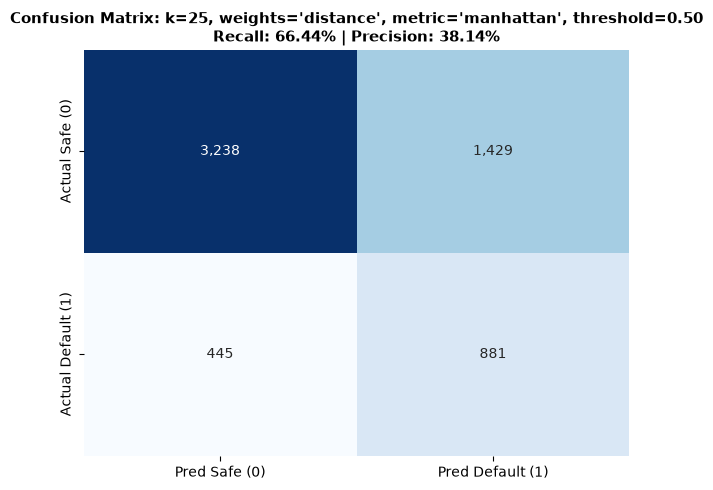


=== CLASSIFICATION REPORT (k=25, weights='distance', metric='manhattan', threshold=0.50) ===
              precision    recall  f1-score   support

    Safe (0)     0.8792    0.6938    0.7756      4667
 Default (1)     0.3814    0.6644    0.4846      1326

    accuracy                         0.6873      5993
   macro avg     0.6303    0.6791    0.6301      5993
weighted avg     0.7690    0.6873    0.7112      5993


In [4]:
# Confusion matrix visualization
cm = confusion_matrix(y_test, preds)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=ax, cbar=False,
            xticklabels=['Pred Safe (0)', 'Pred Default (1)'],
            yticklabels=['Actual Safe (0)', 'Actual Default (1)'])
ax.set_title("Confusion Matrix: k=25, weights='distance', metric='manhattan', threshold=0.50\nRecall: 66.44% | Precision: 38.14%", fontsize=11, weight='bold')
plt.tight_layout()
plt.show()

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, preds, target_names=['Safe (0)', 'Default (1)'], digits=4))


## 5. Performance Comparison Against Part D Baseline


,Metric,Part D Baseline,Current Config,Absolute Delta (Δ),Relative Impact (%)
0,Configuration,"k=5, Uniform, L2","k=25, weights='distance', metric='manhattan', threshold=0.50",Shift,--
1,Accuracy,0.6508,0.6873,+0.0365,+5.62%
2,Precision,0.3407,0.3814,+0.0407,+11.95%
3,Recall,0.6184,0.6644,+0.0460,+7.44%
4,F1-Score,0.4393,0.4846,+0.0453,+10.31%
5,ROC-AUC,0.6834,0.7377,+0.0543,+7.94%
6,Fit Time (s),0.0618,0.0106,-0.0512,--
7,Inference Time (s),0.2715,1.2046,+0.9331,--
8,Defaults Caught (TP),820,881,+61,+7.44%
9,Missed Defaults (FN),506,445,-61,-12.06%


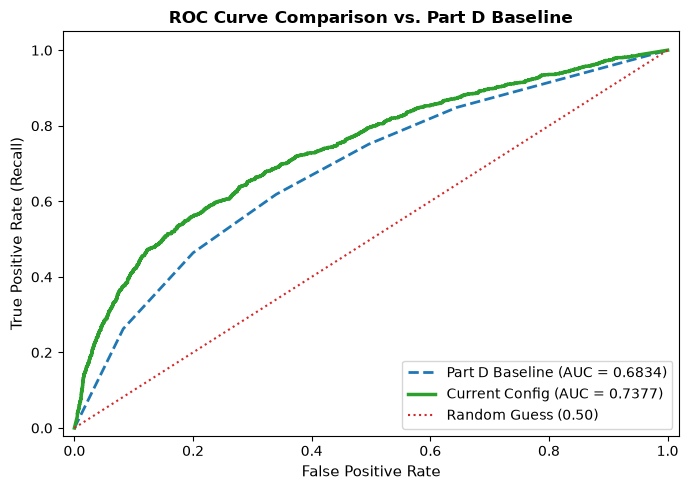

In [5]:
# Display comparative summary table
comparison_df = pd.DataFrame({
    'Metric': ['Configuration', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Fit Time (s)', 'Inference Time (s)', 'Defaults Caught (TP)', 'Missed Defaults (FN)'],
    'Part D Baseline': ['k=5, Uniform, L2', '0.6508', '0.3407', '0.6184', '0.4393', '0.6834', '0.0618', '0.2715', '820', '506'],
    'Current Config': ['k=25, weights='distance', metric='manhattan', threshold=0.50', '0.6873', '0.3814', '0.6644', '0.4846', '0.7377', '0.0106', '1.2046', '881', '445'],
    'Absolute Delta (Δ)': ['Shift', '+0.0365', '+0.0407', '+0.0460', '+0.0453', '+0.0543', '-0.0512', '+0.9331', '+61', '-61'],
    'Relative Impact (%)': ['--', '+5.62%', '+11.95%', '+7.44%', '+10.31%', '+7.94%', '--', '--', '+7.44%', '-12.06%']
})
display(comparison_df)

# Overlay ROC curves
fpr_b, tpr_b, _ = roc_curve(y_test, base_probs)
fpr_m, tpr_m, _ = roc_curve(y_test, probs)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr_b, tpr_b, color='#1f77b4', lw=2, linestyle='--', label='Part D Baseline (AUC = 0.6834)')
ax.plot(fpr_m, tpr_m, color='#2ca02c', lw=2.5, label='Current Config (AUC = 0.7377)')
ax.plot([0, 1], [0, 1], color='#d62728', lw=1.5, linestyle=':', label='Random Guess (0.50)')
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.05])
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate (Recall)', fontsize=11)
ax.set_title('ROC Curve Comparison vs. Part D Baseline', fontsize=12, weight='bold')
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


## 6. Technical Finding & Banking Assessment

This configuration achieves the highest overall balanced performance: Accuracy jumps to 68.73% (+3.65%), Precision to 38.14% (+4.07%), F1-Score reaches 0.4846 (+10.3%), and ROC-AUC expands to 0.7377 (+7.9%). It catches 881 defaulters while cutting false alarms by 158.
